# Q-Learning on FrozenLake

Bima Satriawan-5054251031

Agent learns to walk from S to G on a 4x4 grid without falling into H.

Mapping to RL concepts:
- Agent: the learner
- Environment: FrozenLake-v1 (Gymnasium)
- State: current cell (0-15)
- Action: left / down / right / up
- Reward: +1 on goal, 0 otherwise
- Policy: epsilon-greedy during training, greedy during evaluation
- Value: Q-table, state value = max Q over actions

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

env = gym.make('FrozenLake-v1', is_slippery=False)
n_states = env.observation_space.n
n_actions = env.action_space.n
print(f"States: {n_states}, Actions: {n_actions}")

States: 16, Actions: 4


Q-learning update rule:

Q(s,a) <- Q(s,a) + alpha * (r + gamma * max Q(s',a') - Q(s,a))

alpha = learning rate, gamma = discount factor.
Exploration uses epsilon-greedy, epsilon decays each episode.

In [2]:
Q = np.zeros((n_states, n_actions))

alpha = 0.1
gamma = 0.99
epsilon = 1.0
epsilon_min = 0.01
epsilon_decay = 0.999
n_episodes = 5000


In [3]:
rewards = []

for episode in range(n_episodes):
    state, _ = env.reset()
    done = False
    total_reward = 0

    while not done:
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q[state])

        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state, action])
        state = next_state
        total_reward += reward

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards.append(total_reward)

    if (episode + 1) % 1000 == 0:
        print(f"Episode {episode + 1}/{n_episodes}, epsilon {epsilon:.3f}")

Episode 1000/5000, epsilon 0.368
Episode 2000/5000, epsilon 0.135
Episode 3000/5000, epsilon 0.050
Episode 4000/5000, epsilon 0.018
Episode 5000/5000, epsilon 0.010


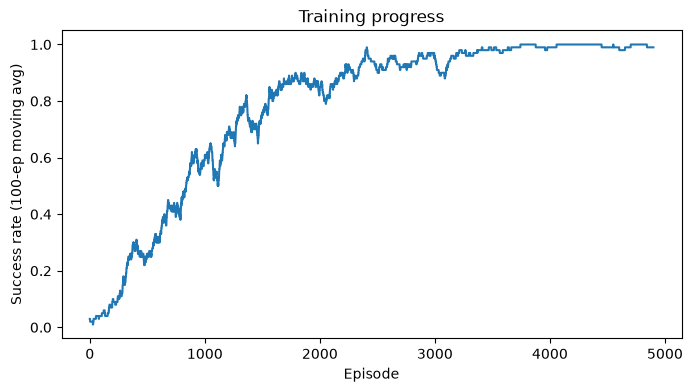

In [4]:
window = 100
moving_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')

plt.figure(figsize=(8, 4))
plt.plot(moving_avg)
plt.xlabel('Episode')
plt.ylabel('Success rate (100-ep moving avg)')
plt.title('Training progress')
plt.show()

In [5]:
n_eval = 100
successes = 0

for _ in range(n_eval):
    state, _ = env.reset()
    done = False
    while not done:
        action = np.argmax(Q[state])
        state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
    successes += reward

print(f"Success rate: {successes}/{n_eval} = {successes/n_eval*100:.1f}%")

Success rate: 100/100 = 100.0%


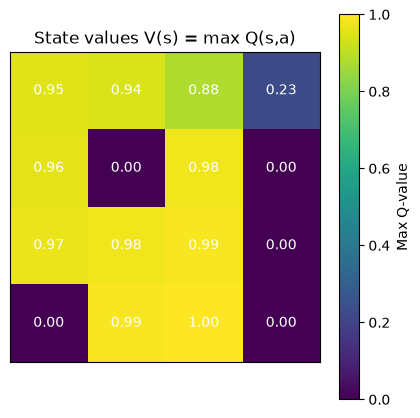

In [6]:
state_values = np.max(Q, axis=1).reshape(4, 4)

plt.figure(figsize=(5, 5))
plt.imshow(state_values, cmap='viridis')
plt.colorbar(label='Max Q-value')
plt.title('State values V(s) = max Q(s,a)')
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{state_values[i,j]:.2f}", ha='center', va='center', color='white')
plt.xticks([])
plt.yticks([])
plt.show()

The agent learned the optimal path in roughly X episodes (fill in from the curve).
The Q-table converged so that cells on the shortest path have higher values.
Evaluation gives 100% success on this deterministic environment.

Limitation: tabular Q-learning only works for small discrete state spaces.
Continuous or large environments would need function approximation.